# Rigid-Bar Network Shear Modulus G(z)



| File | Produced by | Columns (tab-separated) |
|---|---|---|
| `G_curvature_vs_z.dat` | `gmod` mode; one row per (realization, dgamma) | `z  Nc  dgamma  G_fd  Gamma0  iters  residual_err` |
| `<network>_nve.dat` | `nve` mode; one file per invocation | 3 `#`-comment header lines, then `step  KE  max_bar_err  max_vel_constraint  sigma_xy` |

In [1]:
import glob
from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

plt.rcParams.update({
    "figure.dpi": 100,
    "font.size": 11,
    "axes.grid": True,
    "grid.alpha": 0.3,
})

In [2]:
DATA_DIR = Path(".")
FIGURE_DIR = Path("./figures")
SAVE_FIGURES = True
FIGURE_DPI = 300
# The C code reports G_fd for several dgamma (strain-step) values per realization. This only *selects* which already-computed dgamma is used
# for the headline G(z) curve (Figure 1); it's a display choice, not a new calculation.
GMOD_DGAMMA_SELECT = "min"
#min->1e-6
#max->1e-3

# Minimum number of realizations required at a given (z, dgamma) before
# Section 6 stops flagging it as a thin ensemble. 0 disables the check.
MIN_N_WARN = 5

# Rolling-average window (in output rows, not steps) used to smooth
# the raw thermally-fluctuating stress signal in Figure 4.
STRESS_SMOOTHING_WINDOW = 50

FIGURE_DIR.mkdir(parents=True, exist_ok=True)

## Detect Output Files

In [3]:
gmod_path = DATA_DIR / "G_curvature_vs_z.dat"
nve_paths = sorted(glob.glob(str(DATA_DIR / "*_nve.dat")))
network_paths = sorted(
    p for p in glob.glob(str(DATA_DIR / "*.dat"))
    if not p.endswith("_nve.dat") and Path(p).name != gmod_path.name
)
have_gmod = gmod_path.exists()
have_nve = len(nve_paths) > 0
have_network = len(network_paths) > 0
print(f"GMOD     G_curvature_vs_z.dat : {'found' if have_gmod else 'NOT FOUND'}  ({gmod_path})")
print(f"NVE      *_nve.dat            : {len(nve_paths)} file(s)")
for p in nve_paths:
    print(f"  - {p}")
print(f"NETWORK  topology *.dat       : {len(network_paths)} file(s)")
for p in network_paths:
    print(f"  - {p}")


GMOD     G_curvature_vs_z.dat : found  (G_curvature_vs_z.dat)
NVE      *_nve.dat            : 7 file(s)
  - floppy_network_N1600_z2.100_s00000_nve.dat
  - floppy_network_N1600_z2.400_s00000_nve.dat
  - floppy_network_N1600_z2.800_s00000_nve.dat
  - floppy_network_N1600_z3.200_s00000_nve.dat
  - floppy_network_N1600_z3.600_s00000_nve.dat
  - floppy_network_N1600_z3.800_s00000_nve.dat
  - floppy_network_N1600_z3.900_s00000_nve.dat
NETWORK  topology *.dat       : 9 file(s)
  - floppy_network_N1600_z2.100_s00000.dat
  - floppy_network_N1600_z2.400_s00000.dat
  - floppy_network_N1600_z2.800_s00000.dat
  - floppy_network_N1600_z3.200_s00000.dat
  - floppy_network_N1600_z3.600_s00000.dat
  - floppy_network_N1600_z3.800_s00000.dat
  - floppy_network_N1600_z3.800_s00001.dat
  - floppy_network_N1600_z3.800_s00002.dat
  - floppy_network_N1600_z3.900_s00000.dat


## Load GMOD Results

In [4]:
GMOD_COLUMNS = ["z", "Nc", "dgamma", "G_fd", "Gamma0", "iters", "residual_err"]

def load_gmod(path):
    """Load G_curvature_vs_z.dat: one row per (realization, dgamma) pair."""
    df = pd.read_csv(path, sep="\t")
    missing = set(GMOD_COLUMNS) - set(df.columns)
    if missing:
        raise ValueError(f"{path} is missing expected columns: {missing}")
    return df.sort_values(["z", "dgamma"]).reset_index(drop=True)


df_gmod = None
if have_gmod:
    df_gmod = load_gmod(gmod_path)
    print(f"Loaded {len(df_gmod)} row(s): {df_gmod['z'].nunique()} distinct z, "
          f"{df_gmod['dgamma'].nunique()} distinct dgamma")
    display(df_gmod.head(80))
else:
    print("G_curvature_vs_z.dat not found -- skipping GMOD analysis.")

Loaded 28 row(s): 7 distinct z, 4 distinct dgamma


,z,Nc,dgamma,G_fd,Gamma0,iters,residual_err
0,2.1,1680,0.000001,0.012593,0.000042,1,7.669000e-13
1,2.1,1680,0.000010,0.012574,0.000042,2,5.108000e-15
2,2.1,1680,0.000100,0.012572,0.000042,2,5.606000e-15
3,2.1,1680,0.001000,0.012568,0.000042,2,3.081000e-13
4,2.4,1920,0.000001,0.038080,-0.001209,2,7.281000e-15
5,2.4,1920,0.000010,0.038039,-0.001209,2,4.822000e-15
6,2.4,1920,0.000100,0.038036,-0.001209,2,5.391000e-15
7,2.4,1920,0.001000,0.038047,-0.001209,3,4.471000e-15
8,2.8,2240,0.000001,0.072817,-0.001910,2,5.217000e-15
9,2.8,2240,0.000010,0.072829,-0.001910,2,6.695000e-15


## Load NVE Diagnostics

In [5]:
NVE_COLUMNS_FALLBACK = ["step", "KE", "max_bar_err", "max_vel_constraint", "sigma_xy"]

def load_nve(path):
    """Load one *_nve.dat file. Column names are read from the file's own
    '# col: ...' header line rather than hardcoded, so this works for both
    older runs (5 data columns) and runs made with the updated C code that
    also logs total momentum (px, py). z, T, dt are likewise parsed from
    the header lines, not the filename (filenames can get mangled on
    upload). Adds a `time` column (= step * dt, actual units) and, when
    px/py are present, a `P_mag` column (= sqrt(px^2 + py^2))."""
    with open(path) as f:
        header_lines = [f.readline() for _ in range(3)]
    z_match   = re.search(r"z=([0-9.]+)", header_lines[0])
    td_match  = re.search(r"T=([0-9.eE+-]+)\s+dt=([0-9.eE+-]+)", header_lines[1])
    col_match = re.search(r"#\s*col:\s*(.+)", header_lines[2])

    z  = float(z_match.group(1)) if z_match else float("nan")
    T  = float(td_match.group(1)) if td_match else float("nan")
    dt = float(td_match.group(2)) if td_match else float("nan")
    columns = col_match.group(1).split() if col_match else NVE_COLUMNS_FALLBACK

    df = pd.read_csv(path, sep="\t", comment="#", header=None, names=columns)
    df["time"] = df["step"] * dt

    has_momentum = ("px" in df.columns) and ("py" in df.columns)
    if has_momentum:
        df["P_mag"] = np.sqrt(df["px"]**2 + df["py"]**2)

    return {"df": df, "z": z, "T": T, "dt": dt, "has_momentum": has_momentum}


nve_runs = {}
for p in nve_paths:
    name = Path(p).name
    nve_runs[name] = load_nve(p)
    info = nve_runs[name]
    mom_note = "" if info["has_momentum"] else \
        "  (no momentum columns -- older output format; rerun with the updated C code to get px,py)"
    print(f"Loaded {len(info['df'])} row(s) from {name}  "
          f"(z={info['z']:.4g}, dt={info['dt']:.4g}){mom_note}")

if not nve_paths:
    print("No *_nve.dat files found -- skipping NVE diagnostics.")


Loaded 1001 row(s) from floppy_network_N1600_z2.100_s00000_nve.dat  (z=2.1, dt=0.005)
Loaded 1001 row(s) from floppy_network_N1600_z2.400_s00000_nve.dat  (z=2.4, dt=0.005)
Loaded 1001 row(s) from floppy_network_N1600_z2.800_s00000_nve.dat  (z=2.8, dt=0.005)
Loaded 1001 row(s) from floppy_network_N1600_z3.200_s00000_nve.dat  (z=3.2, dt=0.005)
Loaded 1001 row(s) from floppy_network_N1600_z3.600_s00000_nve.dat  (z=3.6, dt=0.005)
Loaded 1001 row(s) from floppy_network_N1600_z3.800_s00000_nve.dat  (z=3.8, dt=0.005)
Loaded 1001 row(s) from floppy_network_N1600_z3.900_s00000_nve.dat  (z=3.9, dt=0.005)


## Ensemble Statistics

In [6]:
def compute_statistics(df, group_cols, value_col, min_n_warn=5):
    """Group by group_cols and compute mean / std / SEM of value_col.
    The only statistic used anywhere in this notebook."""
    stats = (
        df.groupby(group_cols)[value_col]
        .agg(mean="mean", std="std", n="count")
        .reset_index()
    )
    stats["std"] = stats["std"].fillna(0.0)
    stats["sem"] = stats["std"] / np.sqrt(stats["n"])

    thin = stats[stats["n"] < min_n_warn]
    if min_n_warn > 0 and not thin.empty:
        cols = group_cols if isinstance(group_cols, list) else [group_cols]
        print(f"WARNING: {len(thin)} group(s) have fewer than {min_n_warn} "
              f"realizations -- treat as unreliable until more runs are added:")
        display(thin[cols + ["n"]])

    return stats


gmod_stats = None
if df_gmod is not None:
    gmod_stats = compute_statistics(df_gmod, ["z", "dgamma"], "G_fd", min_n_warn=MIN_N_WARN)
    print("G_fd(z, dgamma) ensemble statistics:")
    display(gmod_stats.head(10))

    # Simple convergence check: what fraction of relaxToConstraintManifold()
    # calls failed to converge (iters == -1) at each z? Worth watching as z
    # approaches z_c = 4, where the Gram matrix N gets ill-conditioned.
    fail_rate = (
        df_gmod.assign(failed=df_gmod["iters"] == -1)
        .groupby("z")["failed"].mean()
        .rename("fail_rate")
        .reset_index()
    )
    print("\nFraction of (realization, dgamma) pairs with iters == -1, by z:")
    display(fail_rate)

,z,dgamma,n
0,2.1,0.000001,1
1,2.1,0.000010,1
2,2.1,0.000100,1
3,2.1,0.001000,1
4,2.4,0.000001,1
5,2.4,0.000010,1
6,2.4,0.000100,1
7,2.4,0.001000,1
8,2.8,0.000001,1
9,2.8,0.000010,1


G_fd(z, dgamma) ensemble statistics:


,z,dgamma,mean,std,n,sem
0,2.1,0.000001,0.012593,0.0,1,0.0
1,2.1,0.000010,0.012574,0.0,1,0.0
2,2.1,0.000100,0.012572,0.0,1,0.0
3,2.1,0.001000,0.012568,0.0,1,0.0
4,2.4,0.000001,0.038080,0.0,1,0.0
5,2.4,0.000010,0.038039,0.0,1,0.0
6,2.4,0.000100,0.038036,0.0,1,0.0
7,2.4,0.001000,0.038047,0.0,1,0.0
8,2.8,0.000001,0.072817,0.0,1,0.0
9,2.8,0.000010,0.072829,0.0,1,0.0



Fraction of (realization, dgamma) pairs with iters == -1, by z:


,z,fail_rate
0,2.1,0.0
1,2.4,0.0
2,2.8,0.0
3,3.2,0.0
4,3.6,0.0
5,3.8,0.0
6,3.9,0.0


## Figures

In [7]:
_saved_figures = []

def save_figure(fig, name):
    """Save fig to FIGURE_DIR/<name>.png if SAVE_FIGURES is True."""
    if not SAVE_FIGURES:
        return None
    FIGURE_DIR.mkdir(parents=True, exist_ok=True)
    out_path = FIGURE_DIR / f"{name}.png"
    fig.savefig(out_path, dpi=FIGURE_DPI, bbox_inches="tight")
    _saved_figures.append(out_path)
    print(f"Saved figure -> {out_path}")
    return out_path

### Figure 0 — Network connectivity maps

One full-size figure per network topology file (looped, not a subplot grid, so each image can be copied individually from the cell output). Highlights the giant percolating cluster vs. disconnected floaters. $N$ and bond count are read directly from each file (not hardcoded), and $z$ is parsed from the filename for the title.


floppy_network_N1600_z2.100_s00000.dat: N=1600  bonds=1680  giant-cluster fraction=97.8%
Saved figure -> figures/fig0_network_floppy_network_N1600_z2.100_s00000.png


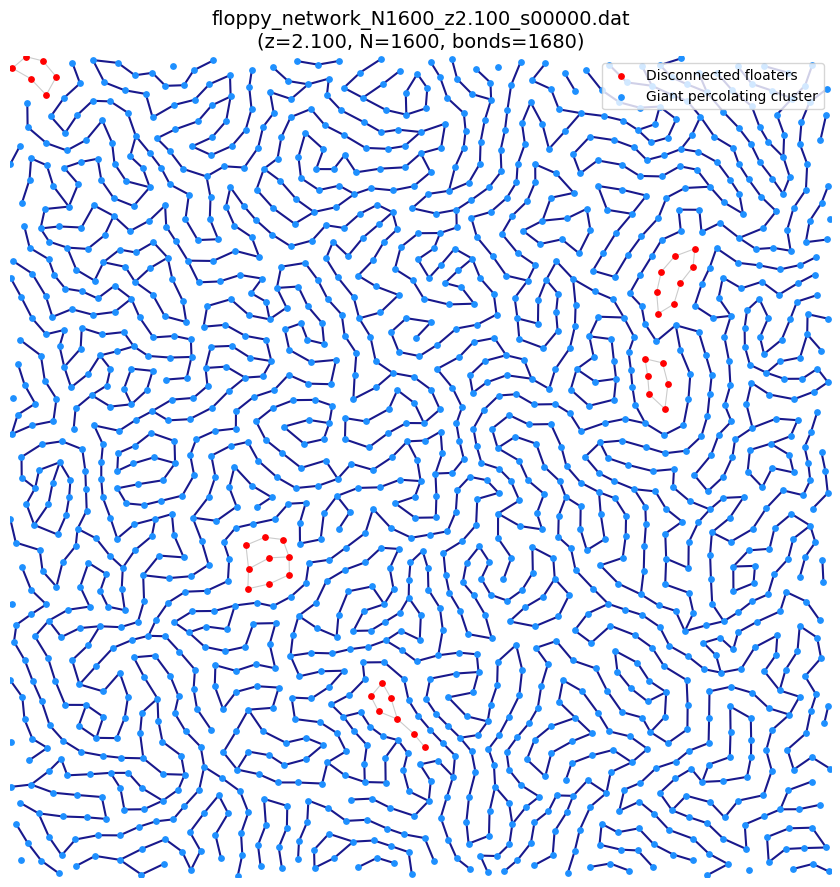

floppy_network_N1600_z2.400_s00000.dat: N=1600  bonds=1920  giant-cluster fraction=100.0%
Saved figure -> figures/fig0_network_floppy_network_N1600_z2.400_s00000.png


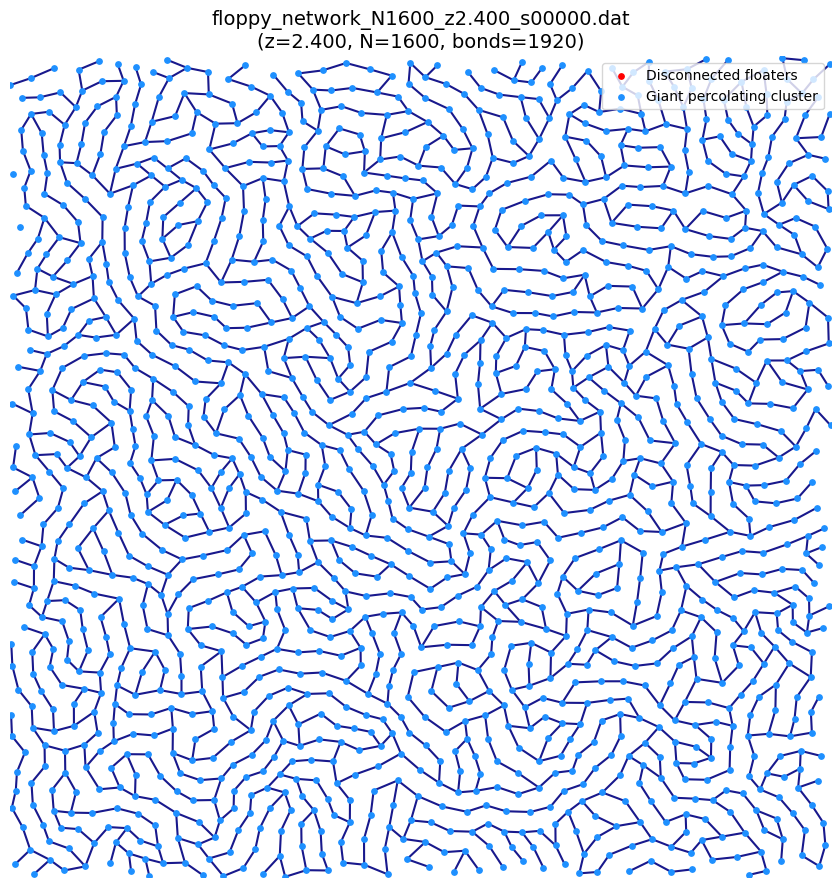

floppy_network_N1600_z2.800_s00000.dat: N=1600  bonds=2240  giant-cluster fraction=100.0%
Saved figure -> figures/fig0_network_floppy_network_N1600_z2.800_s00000.png


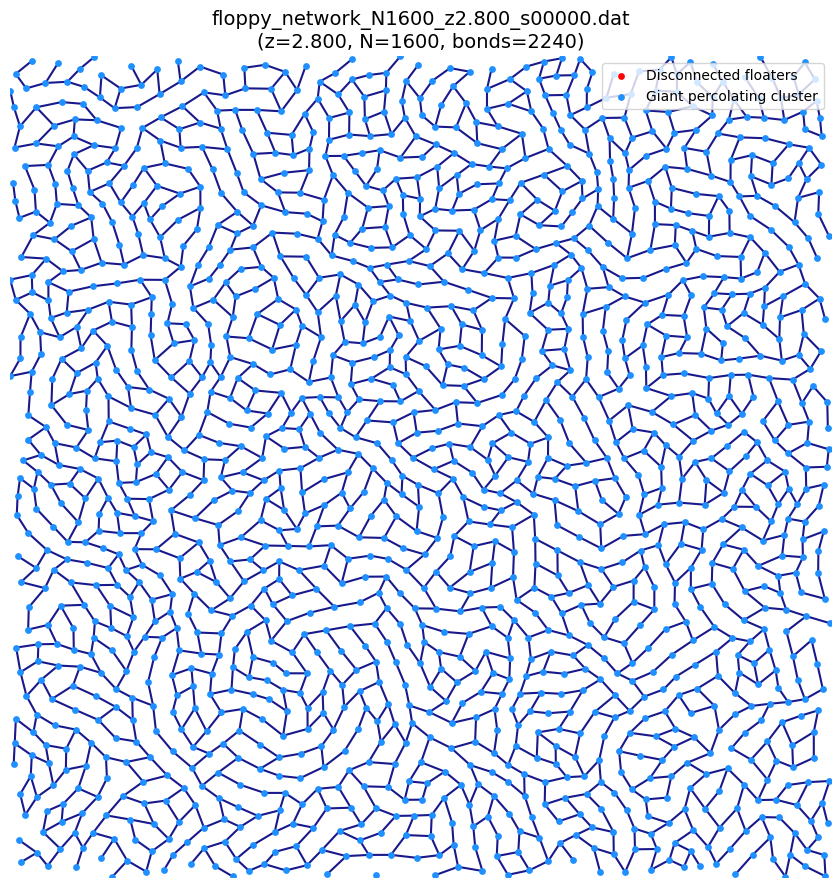

floppy_network_N1600_z3.200_s00000.dat: N=1600  bonds=2560  giant-cluster fraction=100.0%
Saved figure -> figures/fig0_network_floppy_network_N1600_z3.200_s00000.png


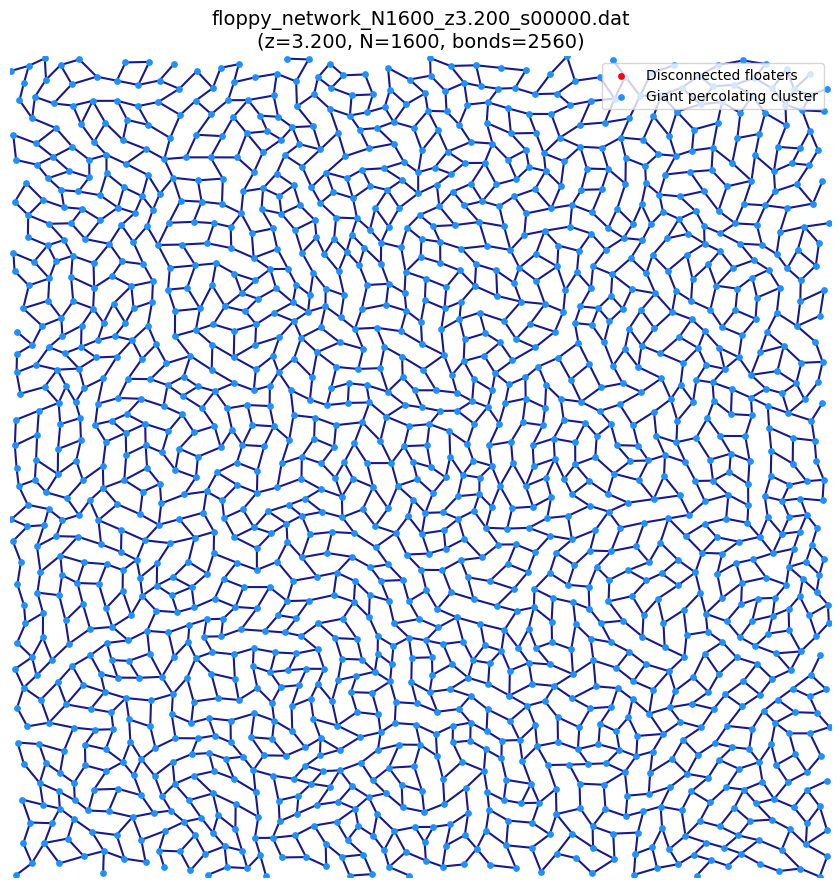

floppy_network_N1600_z3.600_s00000.dat: N=1600  bonds=2880  giant-cluster fraction=100.0%
Saved figure -> figures/fig0_network_floppy_network_N1600_z3.600_s00000.png


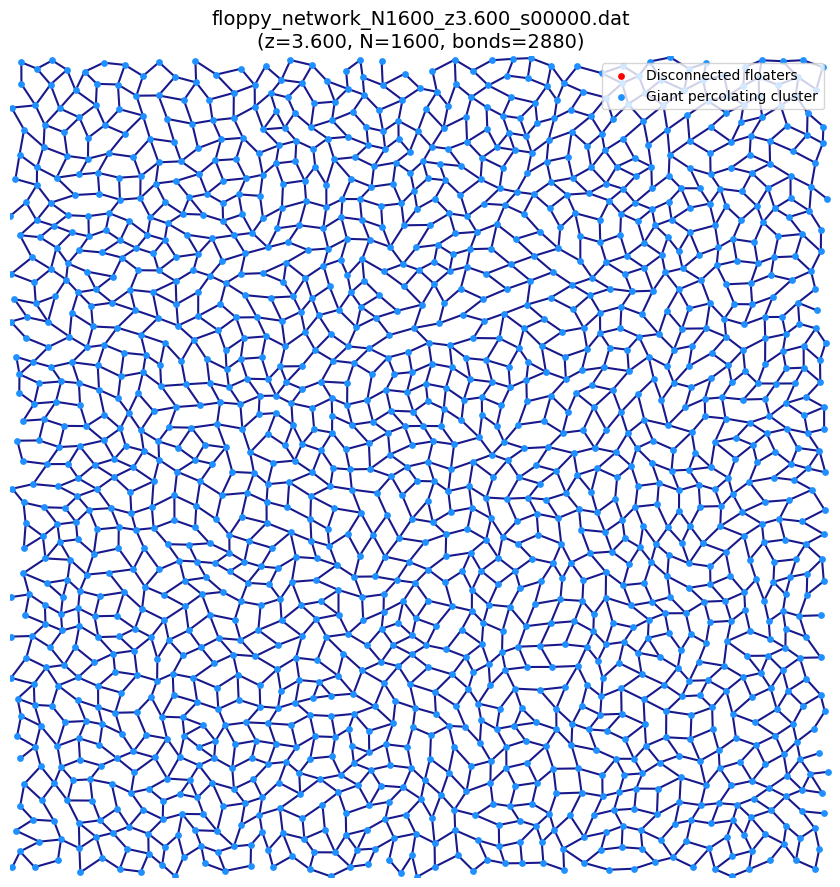

floppy_network_N1600_z3.800_s00000.dat: N=1600  bonds=3040  giant-cluster fraction=100.0%
Saved figure -> figures/fig0_network_floppy_network_N1600_z3.800_s00000.png


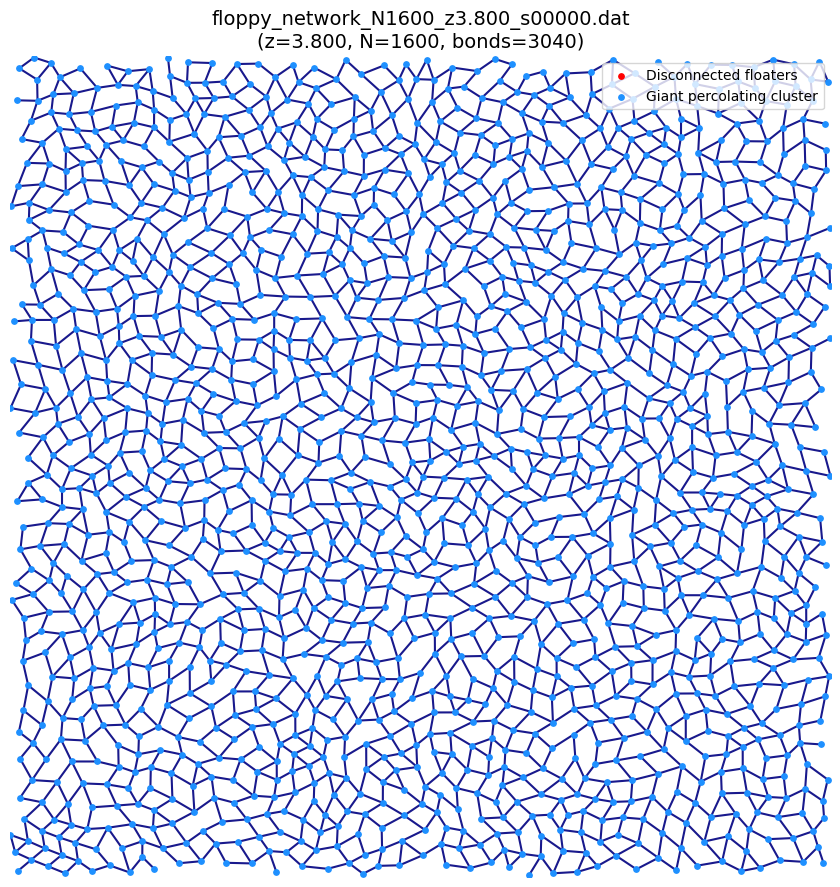

floppy_network_N1600_z3.800_s00001.dat: N=1600  bonds=3040  giant-cluster fraction=100.0%
Saved figure -> figures/fig0_network_floppy_network_N1600_z3.800_s00001.png


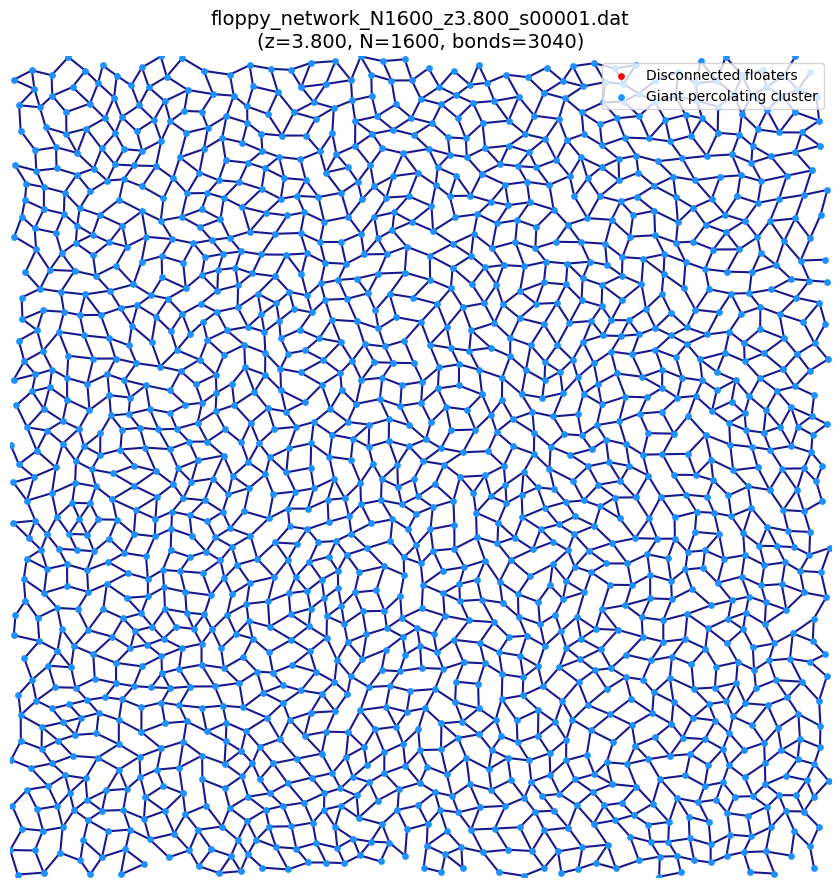

floppy_network_N1600_z3.800_s00002.dat: N=1600  bonds=3040  giant-cluster fraction=100.0%
Saved figure -> figures/fig0_network_floppy_network_N1600_z3.800_s00002.png


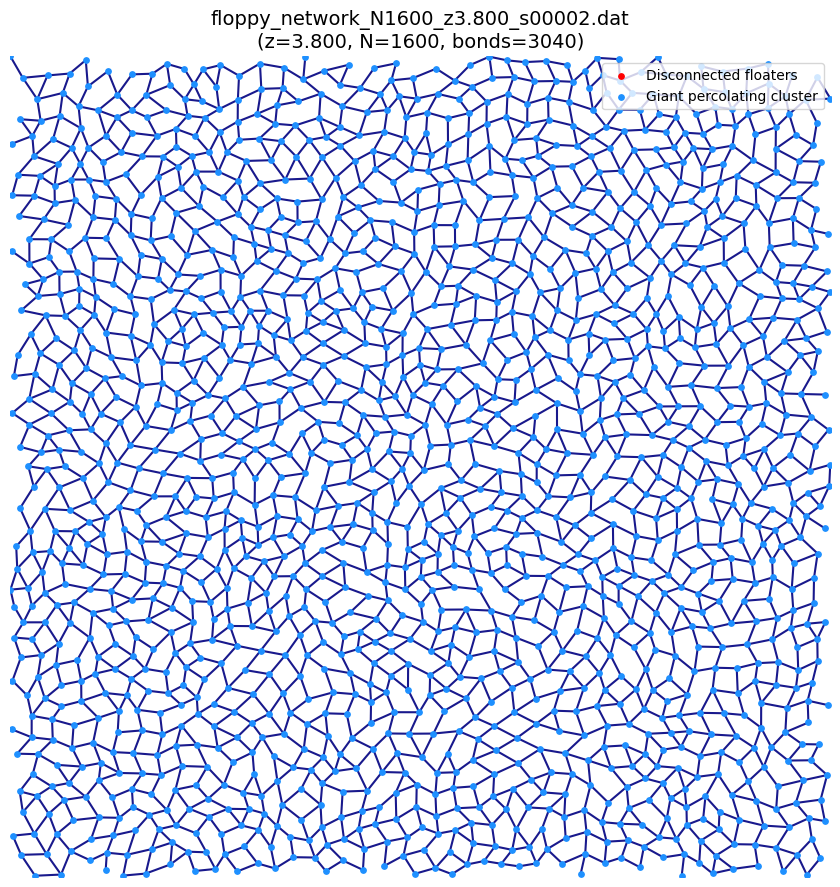

floppy_network_N1600_z3.900_s00000.dat: N=1600  bonds=3120  giant-cluster fraction=100.0%
Saved figure -> figures/fig0_network_floppy_network_N1600_z3.900_s00000.png


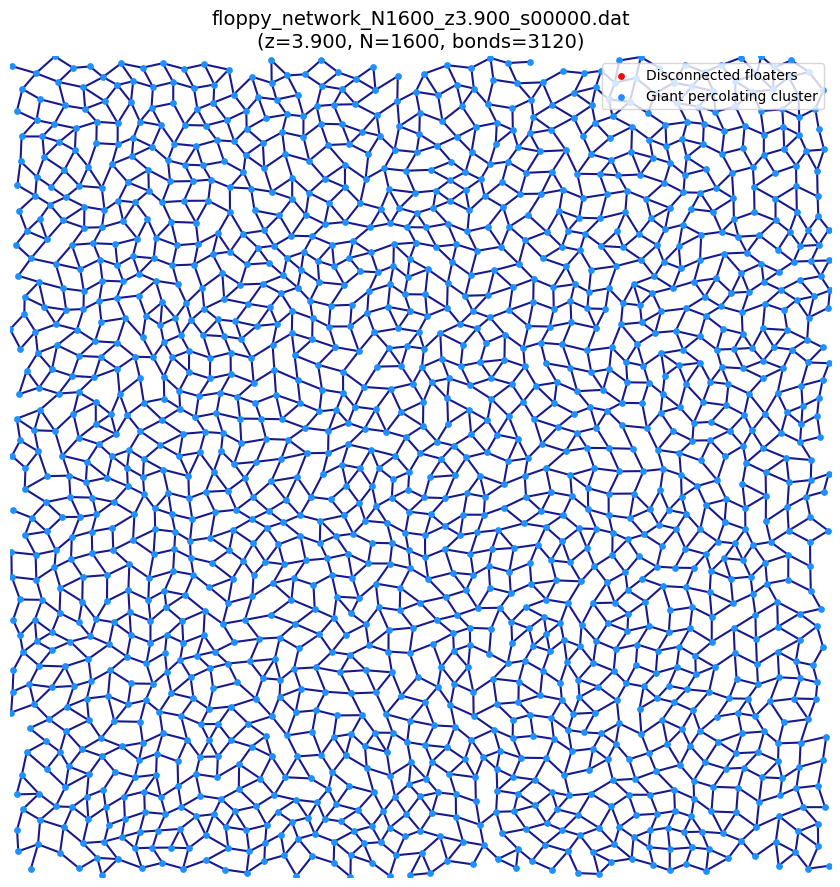

In [8]:
def load_network(path):
    """Parse one network-topology .dat file: box length L, node positions
    (physical units), and bonds. N is *not* assumed -- the node block's
    end is detected by finding the line whose declared edge count equals
    the number of lines actually remaining below it, so this works for
    any N, not just this project's usual N=1600."""
    with open(path) as f:
        lines = [ln for ln in f.read().splitlines() if ln.strip()]
    L = float(lines[0].split()[0])

    edge_count_idx = None
    for k in range(1, len(lines)):
        parts = lines[k].split()
        if len(parts) == 3 and parts[1] == "-1" and parts[2] == "-1":
            try:
                claimed = int(float(parts[0]))
            except ValueError:
                continue
            if claimed == len(lines) - 1 - k:
                edge_count_idx = k
                break
    if edge_count_idx is None:
        raise ValueError(f"{path}: couldn't locate the edge-count line")

    N = edge_count_idx - 1
    nodes = [tuple(float(t) * L for t in lines[k].split()[:2])
             for k in range(1, edge_count_idx)]

    num_edges = int(float(lines[edge_count_idx].split()[0]))
    edges = [tuple(int(t) for t in lines[k].split()[:2])
             for k in range(edge_count_idx + 1, edge_count_idx + 1 + num_edges)]

    return {"L": L, "N": N, "nodes": nodes, "edges": edges}


def plot_network(net, title):
    """Draw the connectivity map for one network, highlighting the giant
    percolating cluster vs. disconnected floaters. Returns (fig, percolation_fraction)."""
    N, L, nodes, edges = net["N"], net["L"], net["nodes"], net["edges"]

    G = nx.Graph()
    G.add_nodes_from(range(N))
    G.add_edges_from(edges)
    components = sorted(nx.connected_components(G), key=len, reverse=True)
    largest_component = components[0] if components else set()
    percolation_fraction = len(largest_component) / N if N else float("nan")

    fig, ax = plt.subplots(figsize=(9, 9))
    lc_edges    = [(u, v) for u, v in edges if u in largest_component and v in largest_component]
    other_edges = [(u, v) for u, v in edges if u not in largest_component or v not in largest_component]

    def draw_edges(edge_list, color, linewidth, alpha=1.0):
        for u, v in edge_list:
            x1, y1 = nodes[u]; x2, y2 = nodes[v]
            if abs(x2 - x1) > L / 2 or abs(y2 - y1) > L / 2:
                continue  # skip periodic wrap-around bonds for a clean picture
            ax.plot([x1, x2], [y1, y2], color=color, lw=linewidth, alpha=alpha, zorder=1)

    draw_edges(other_edges, color="gray", linewidth=0.8, alpha=0.4)
    draw_edges(lc_edges, color="navy", linewidth=1.5, alpha=0.9)

    other_nodes = set(range(N)) - largest_component
    x_other = [nodes[n][0] for n in other_nodes]; y_other = [nodes[n][1] for n in other_nodes]
    x_lc    = [nodes[n][0] for n in largest_component]; y_lc = [nodes[n][1] for n in largest_component]

    ax.scatter(x_other, y_other, color="red", s=15, zorder=3, label="Disconnected floaters")
    ax.scatter(x_lc, y_lc, color="dodgerblue", s=15, zorder=2, label="Giant percolating cluster")

    ax.set_xlim(0, L); ax.set_ylim(0, L)
    ax.set_title(title, fontsize=14)
    ax.legend(loc="upper right", fontsize=10)
    ax.set_aspect("equal")
    ax.axis("off")
    fig.tight_layout()
    return fig, percolation_fraction


if network_paths:
    try:
        import networkx as nx
    except ImportError:
        print("networkx is required for Figure 0 (pip install networkx) -- skipping.")
        network_paths = []

if network_paths:
    for p in network_paths:
        name = Path(p).name
        net = load_network(p)
        z_match = re.search(r"z([0-9.]+)", name)
        z_label = z_match.group(1) if z_match else "unknown"
        fig0, frac = plot_network(
            net, f"{name}\n(z={z_label}, N={net['N']}, bonds={len(net['edges'])})"
        )
        print(f"{name}: N={net['N']}  bonds={len(net['edges'])}  "
              f"giant-cluster fraction={frac*100:.1f}%")
        save_figure(fig0, f"fig0_network_{Path(name).stem}")
        plt.show()
else:
    print("No network topology files found; skipping Figure 0.")


### Figure 1 — Nonlinear shear modulus $G(z)$

Saved figure -> figures/fig1_G_vs_z.png


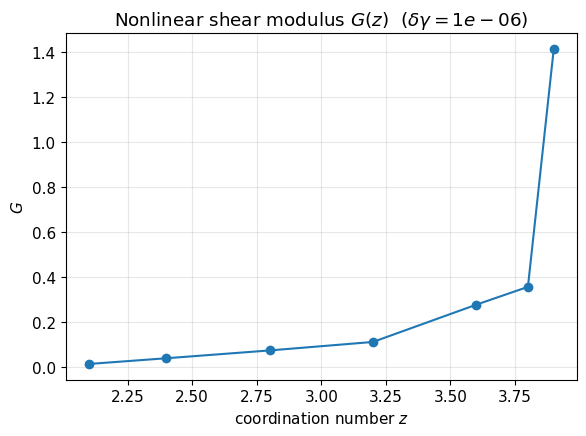

In [9]:
def select_gmod_curve(gmod_stats, select):
    """Pick one G_fd(z) curve out of the (z, dgamma) stats table.
    Only selects among dgamma values the C code already computed."""
    if select == "min":
        dgamma_val = gmod_stats["dgamma"].min()
    elif select == "max":
        dgamma_val = gmod_stats["dgamma"].max()
    else:
        dgamma_val = float(select)
    sub = (
        gmod_stats[np.isclose(gmod_stats["dgamma"], dgamma_val)]
        .sort_values("z")
        .reset_index(drop=True)
    )
    return sub, dgamma_val


fig1 = None
if gmod_stats is not None:
    gmod_curve, dgamma_used = select_gmod_curve(gmod_stats, GMOD_DGAMMA_SELECT)
    fig1, ax1 = plt.subplots(figsize=(6, 4.5))
    ax1.errorbar(gmod_curve["z"], gmod_curve["mean"], yerr=gmod_curve["sem"],
                 marker="o", linestyle="-", capsize=3)
    ax1.set_xlabel(r"coordination number $z$")
    ax1.set_ylabel(r"$G$")
    ax1.set_title(rf"Nonlinear shear modulus $G(z)$  ($\delta\gamma={dgamma_used:.2g}$)")
    fig1.tight_layout()
    save_figure(fig1, "fig1_G_vs_z")
    plt.show()
else:
    print("No GMOD data available; skipping Figure 1.")

### Figure 2 — Finite-difference convergence: does $G_{\rm fd}$ plateau as $\delta\gamma \to 0$?

Saved figure -> figures/fig2_dgamma_convergence.png


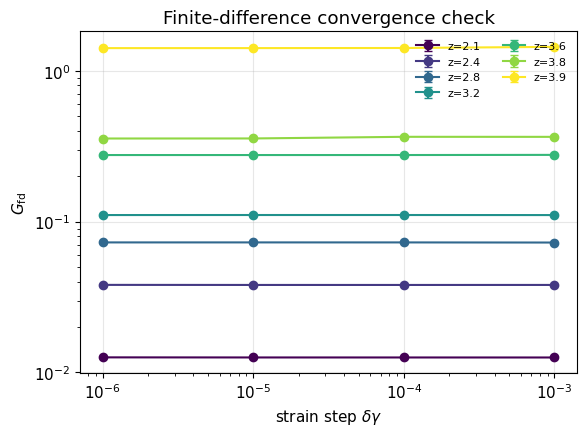

In [10]:
fig2 = None
if gmod_stats is not None and gmod_stats["dgamma"].nunique() > 1:
    fig2, ax2 = plt.subplots(figsize=(6, 4.5))
    z_values = sorted(gmod_stats["z"].unique())
    colors = plt.cm.viridis(np.linspace(0, 1, len(z_values)))
    for z_val, color in zip(z_values, colors):
        sub = gmod_stats[gmod_stats["z"] == z_val].sort_values("dgamma")
        ax2.errorbar(sub["dgamma"], sub["mean"], yerr=sub["sem"],
                     marker="o", color=color, capsize=3, label=f"z={z_val:.3g}")
    ax2.set_xscale("log")
    ax2.set_yscale("log")
    ax2.set_xlabel(r"strain step $\delta\gamma$")
    ax2.set_ylabel(r"$G_{\rm fd}$")
    ax2.set_title("Finite-difference convergence check")
    ax2.legend(frameon=False, fontsize=8, ncol=2)
    n_nonpositive = (gmod_stats["mean"] <= 0).sum()
    if n_nonpositive:
        print(f"NOTE: {n_nonpositive} point(s) have G_fd <= 0 and will not "
              f"appear on this log-scale plot (matplotlib drops them silently "
              f"rather than erroring).")
    fig2.tight_layout()
    save_figure(fig2, "fig2_dgamma_convergence")
    plt.show()
else:
    print("Fewer than 2 dgamma values available; skipping Figure 2.")

### Figure 3 — NVE diagnostics: energy and constraint drift over a run

Saved figure -> figures/fig3_nve_diagnostics.png


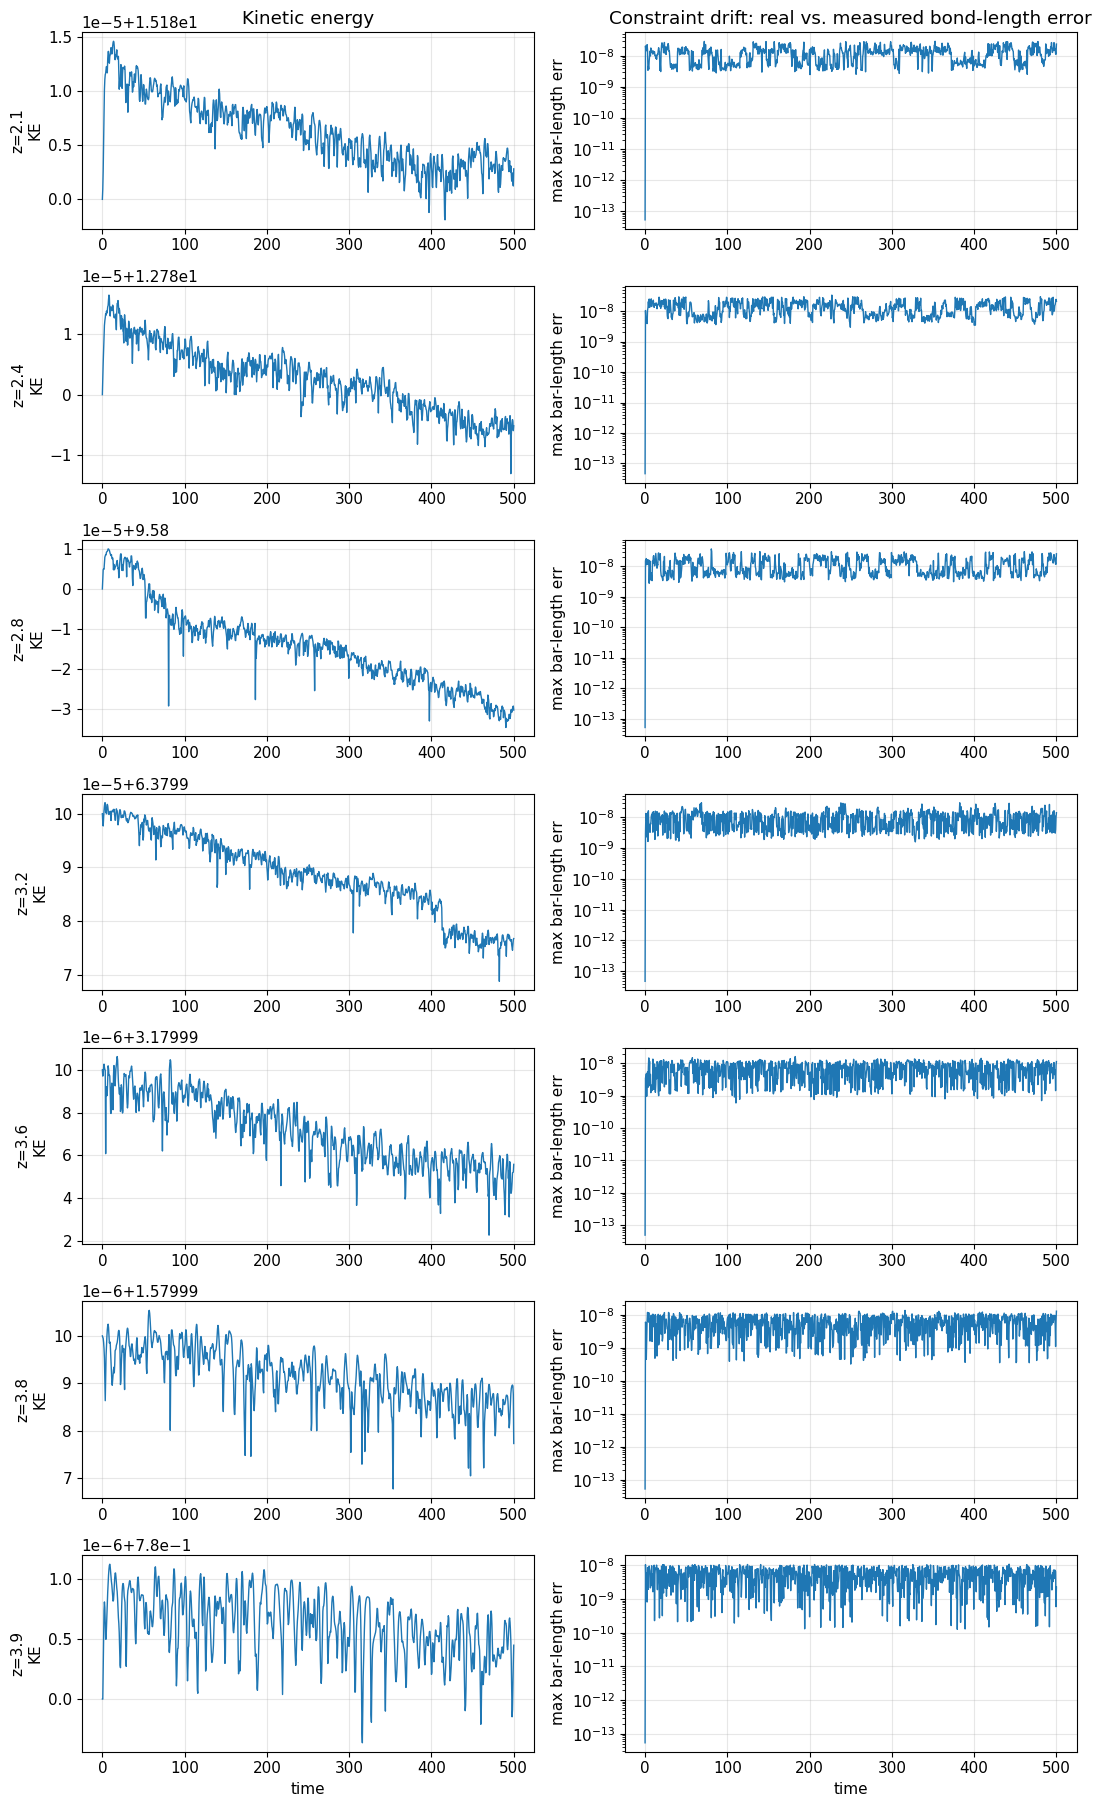

In [11]:
fig3 = None
if nve_runs:
    z_groups = {}
    for name, info in nve_runs.items():
        z_groups.setdefault(info["z"], []).append(name)
    z_values = sorted(z_groups)

    fig3, axes = plt.subplots(len(z_values), 2, figsize=(11, 2.6 * len(z_values)), squeeze=False)
    for row, z in enumerate(z_values):
        axKE, axErr = axes[row]
        for name in z_groups[z]:
            df = nve_runs[name]["df"]
            axKE.plot(df["time"], df["KE"], linewidth=1, label=name)
            axErr.semilogy(df["time"], df["max_bar_err"], linewidth=1, label=name)
        axKE.set_ylabel(f"z={z:g}\nKE")
        axErr.set_ylabel("max bar-length err")
        if len(z_groups[z]) > 1:
            axKE.legend(frameon=False, fontsize=6)
        if row == 0:
            axKE.set_title("Kinetic energy")
            axErr.set_title("Constraint drift: real vs. measured bond-length error")
    axes[-1, 0].set_xlabel("time")
    axes[-1, 1].set_xlabel("time")
    fig3.tight_layout()
    save_figure(fig3, "fig3_nve_diagnostics")
    plt.show()
else:
    print("No NVE data available; skipping Figure 3.")


### Figure 4 — Stress vs. physical time

One full-size figure per run (looped, not a subplot grid -- each image can be copied individually from the cell output), then a final combined figure overlaying the smoothed curves for every $z$ together. Uses the same `nve_runs` loaded above (real `time`, from each file's own header `dt`), rather than a separate hardcoded reload.


Saved figure -> figures/fig4_stress_vs_time_floppy_network_N1600_z2.100_s00000_nve.png


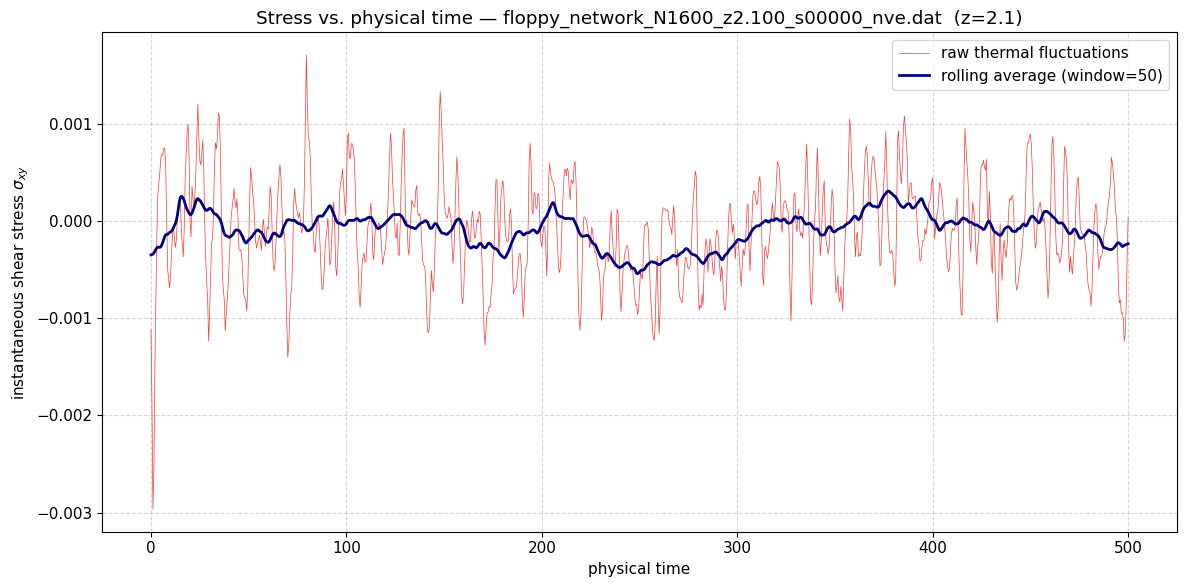

Saved figure -> figures/fig4_stress_vs_time_floppy_network_N1600_z2.400_s00000_nve.png


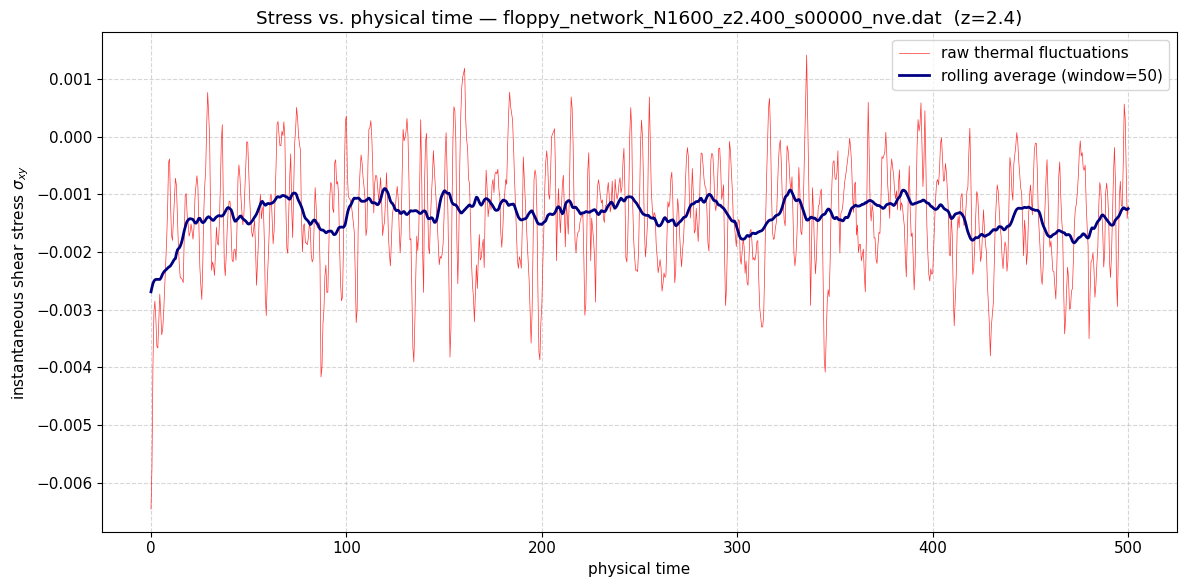

Saved figure -> figures/fig4_stress_vs_time_floppy_network_N1600_z2.800_s00000_nve.png


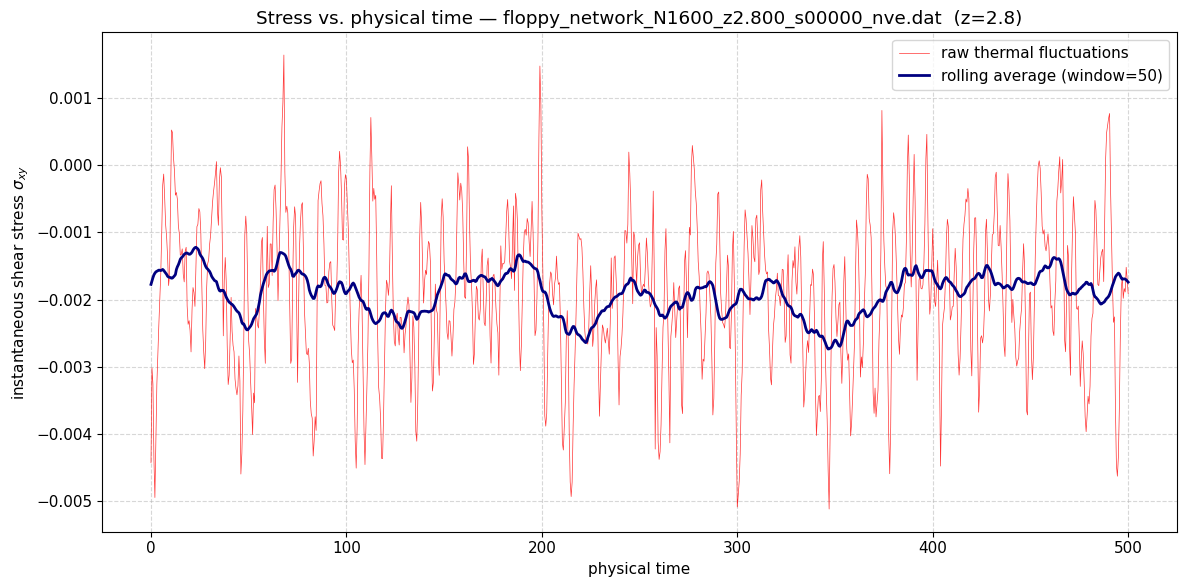

Saved figure -> figures/fig4_stress_vs_time_floppy_network_N1600_z3.200_s00000_nve.png


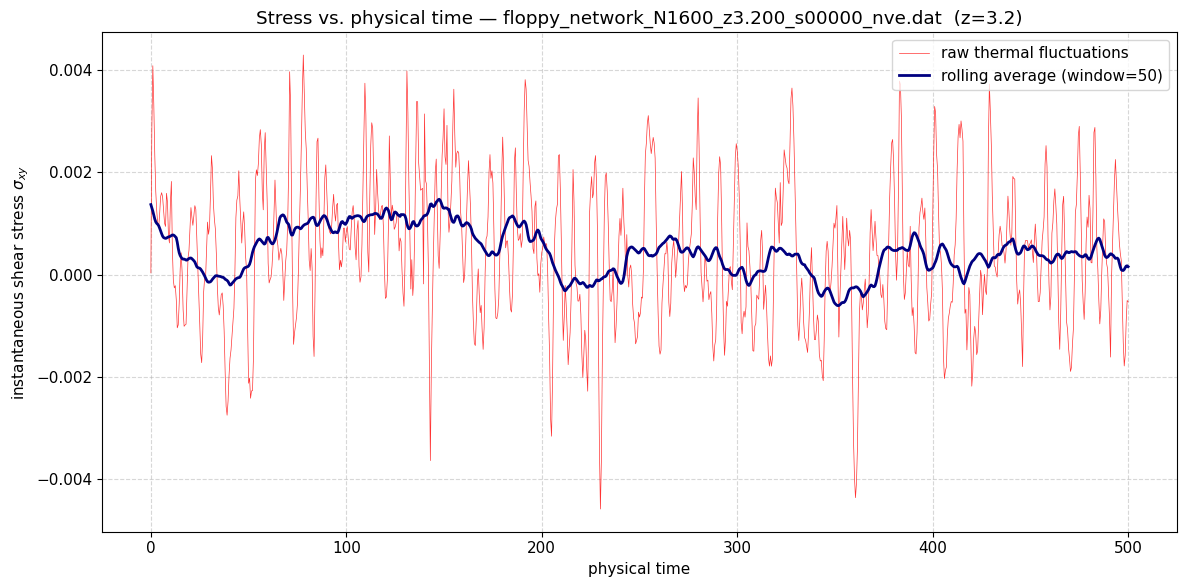

Saved figure -> figures/fig4_stress_vs_time_floppy_network_N1600_z3.600_s00000_nve.png


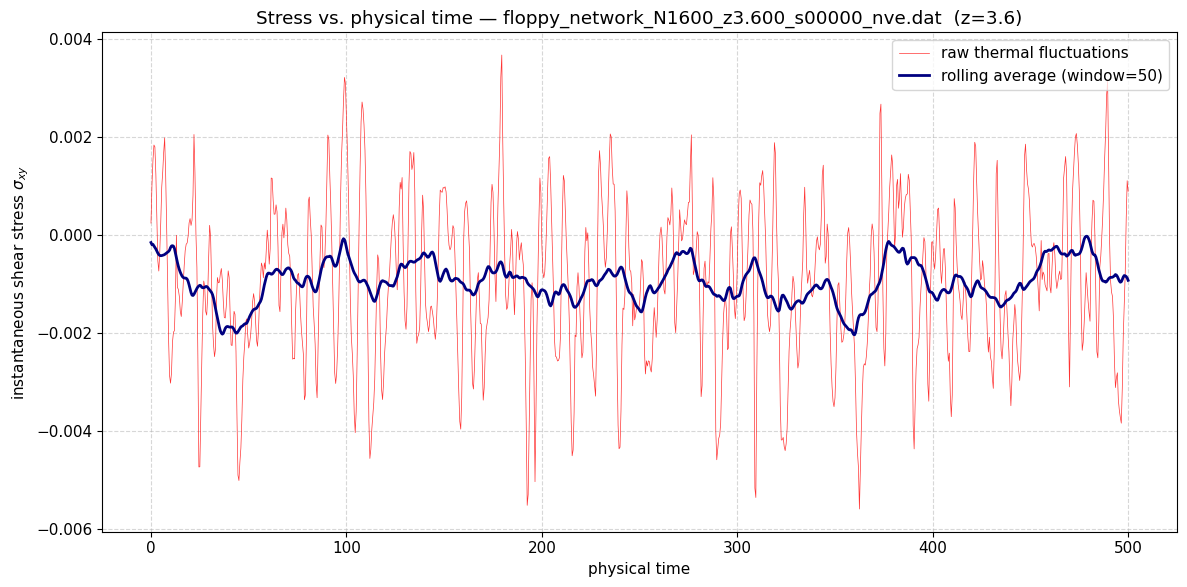

Saved figure -> figures/fig4_stress_vs_time_floppy_network_N1600_z3.800_s00000_nve.png


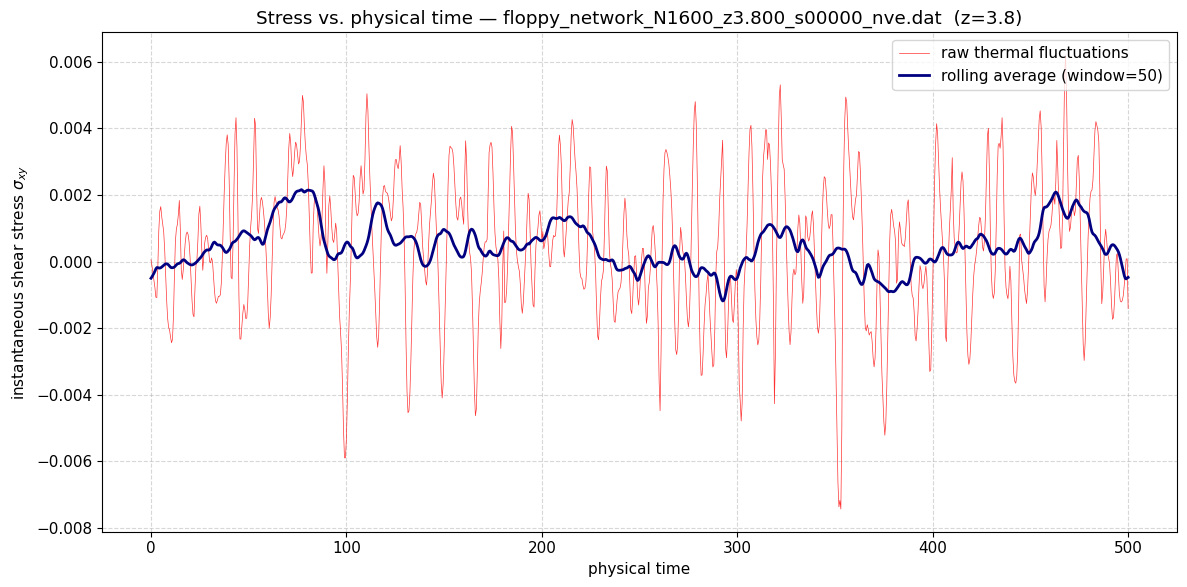

Saved figure -> figures/fig4_stress_vs_time_floppy_network_N1600_z3.900_s00000_nve.png


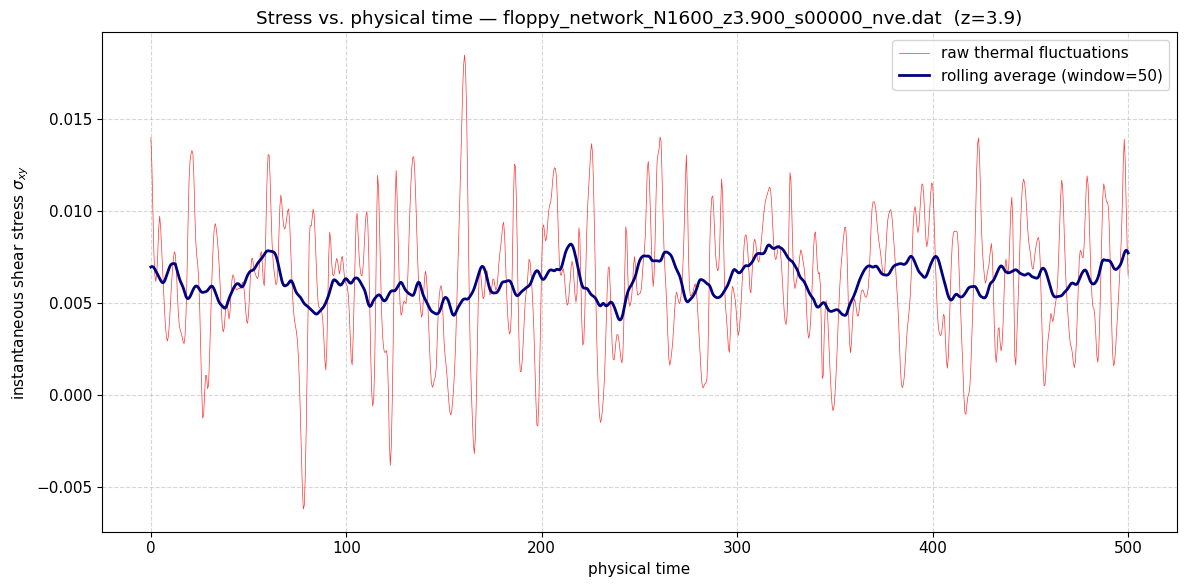

Saved figure -> figures/fig4_stress_vs_time_all_z.png


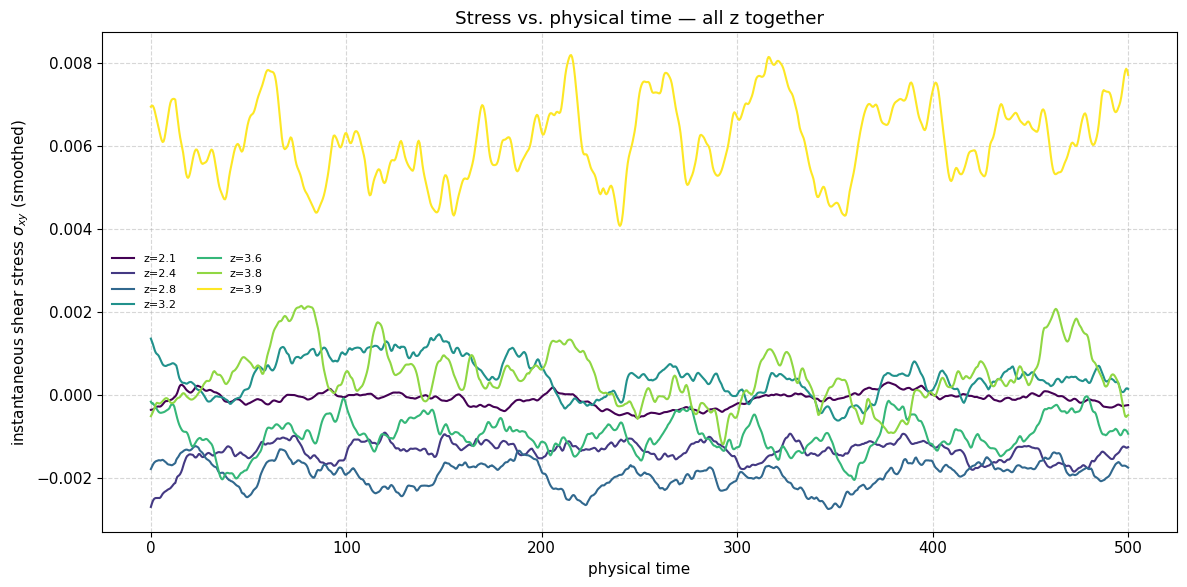

In [12]:
fig4_runs = []
if nve_runs:
    for name, info in sorted(nve_runs.items(), key=lambda kv: kv[1]["z"]):
        df = info["df"]
        smooth = df["sigma_xy"].rolling(window=STRESS_SMOOTHING_WINDOW, center=True, min_periods=1).mean()

        fig4, ax4 = plt.subplots(figsize=(12, 6))
        ax4.plot(df["time"], df["sigma_xy"], color="red", alpha=0.8, linewidth=0.5,
                 label="raw thermal fluctuations")
        ax4.plot(df["time"], smooth, color="navy", alpha=1.0, linewidth=2,
                 label=f"rolling average (window={STRESS_SMOOTHING_WINDOW})")
        ax4.set_xlabel("physical time")
        ax4.set_ylabel(r"instantaneous shear stress $\sigma_{xy}$")
        ax4.set_title(f"Stress vs. physical time \u2014 {name}  (z={info['z']:.3g})")
        ax4.legend(loc="upper right", frameon=True)
        ax4.grid(True, linestyle="--", alpha=0.5)
        fig4.tight_layout()
        save_figure(fig4, f"fig4_stress_vs_time_{Path(name).stem}")
        plt.show()
        fig4_runs.append((name, info["z"], df, smooth))

    # Combined view: every z on one plot, so trends across z can be compared directly.
    fig4_all, ax4_all = plt.subplots(figsize=(12, 6))
    colors = plt.cm.viridis(np.linspace(0, 1, len(fig4_runs)))
    for (name, z, df, smooth), color in zip(fig4_runs, colors):
        ax4_all.plot(df["time"], smooth, color=color, linewidth=1.5, label=f"z={z:.3g}")
    ax4_all.set_xlabel("physical time")
    ax4_all.set_ylabel(r"instantaneous shear stress $\sigma_{xy}$ (smoothed)")
    ax4_all.set_title("Stress vs. physical time \u2014 all z together")
    ax4_all.legend(frameon=False, fontsize=8, ncol=2)
    ax4_all.grid(True, linestyle="--", alpha=0.5)
    fig4_all.tight_layout()
    save_figure(fig4_all, "fig4_stress_vs_time_all_z")
    plt.show()
else:
    print("No NVE data available; skipping Figure 4.")


### Figure 5 — Energy and momentum conservation checks

Energy: $H=\tfrac12\langle v|v\rangle$ is purely kinetic here, so plotting the relative drift $(KE-KE_0)/KE_0$ over the run *is* the energy-conservation check. Momentum: $|P|=|\sum_i \vec v_i|$ (unit mass) should sit at machine epsilon for the whole run -- every internal force comes from $S^T|f\rangle$, which places equal-and-opposite contributions on each bar's two endpoints, so RATTLE has no mechanism to inject net momentum. This is checked empirically below rather than assumed; older runs logged before the C code was updated won't have `px`, `py` and are flagged rather than silently skipped.


floppy_network_N1600_z2.100_s00000_nve.dat: max |relative KE drift| = 9.598e-07
floppy_network_N1600_z2.100_s00000_nve.dat: max |P| = 2.975e-13
floppy_network_N1600_z2.400_s00000_nve.dat: max |relative KE drift| = 1.282e-06
floppy_network_N1600_z2.400_s00000_nve.dat: max |P| = 3.176e-13
floppy_network_N1600_z2.800_s00000_nve.dat: max |relative KE drift| = 3.615e-06
floppy_network_N1600_z2.800_s00000_nve.dat: max |P| = 2.753e-13
floppy_network_N1600_z3.200_s00000_nve.dat: max |relative KE drift| = 4.889e-06
floppy_network_N1600_z3.200_s00000_nve.dat: max |P| = 7.785e-14
floppy_network_N1600_z3.600_s00000_nve.dat: max |relative KE drift| = 2.431e-06
floppy_network_N1600_z3.600_s00000_nve.dat: max |P| = 9.432e-14
floppy_network_N1600_z3.800_s00000_nve.dat: max |relative KE drift| = 2.043e-06
floppy_network_N1600_z3.800_s00000_nve.dat: max |P| = 6.537e-14
floppy_network_N1600_z3.900_s00000_nve.dat: max |relative KE drift| = 1.436e-06
floppy_network_N1600_z3.900_s00000_nve.dat: max |P| = 8.

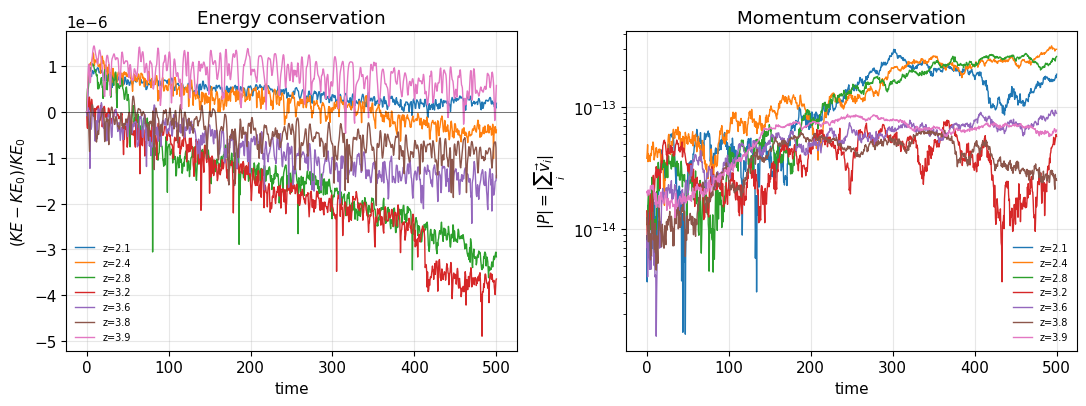

In [13]:
fig5 = None
if nve_runs:
    runs_with_momentum = {name: info for name, info in nve_runs.items() if info["has_momentum"]}
    if not runs_with_momentum:
        print("None of the loaded runs have momentum columns (px, py) -- rerun the "
              "updated C code to get momentum-conservation data. The energy-drift "
              "panel below is still shown.")

    fig5, (axE, axP) = plt.subplots(1, 2, figsize=(11, 4.2))
    for name, info in sorted(nve_runs.items(), key=lambda kv: kv[1]["z"]):
        df = info["df"]
        KE0 = df["KE"].iloc[0]
        rel_drift = (df["KE"] - KE0) / KE0
        axE.plot(df["time"], rel_drift, linewidth=1, label=f"z={info['z']:.3g}")
        print(f"{name}: max |relative KE drift| = {rel_drift.abs().max():.3e}")

        if info["has_momentum"]:
            axP.semilogy(df["time"], df["P_mag"], linewidth=1, label=f"z={info['z']:.3g}")
            print(f"{name}: max |P| = {df['P_mag'].max():.3e}")

    axE.axhline(0, color="k", linewidth=0.7, alpha=0.5)
    axE.set_xlabel("time"); axE.set_ylabel(r"$(KE - KE_0)/KE_0$")
    axE.set_title("Energy conservation")
    axE.legend(frameon=False, fontsize=7)

    axP.set_xlabel("time"); axP.set_ylabel(r"$|P| = |\sum_i \vec v_i|$")
    axP.set_title("Momentum conservation")
    if runs_with_momentum:
        axP.legend(frameon=False, fontsize=7)
    else:
        axP.text(0.5, 0.5, "no momentum data\n(older output format)",
                 ha="center", va="center", transform=axP.transAxes)

    fig5.tight_layout()
    save_figure(fig5, "fig5_conservation_checks")
    plt.show()
else:
    print("No NVE data available; skipping Figure 5.")
